# **TUGAS 2**
## **Pemodelan dan Pembelajaran Mesin - 03**
---

### **KELOMPOK 4**

1. **Muhammad Ikhsan Maulana** (NPM: )
2. **Hanna Malika Az-Zahra** (NPM: 2206055914)
3. **Matthew Tristan Hutapea** (NPM:2206056085)
4. **Syafiq Khanafi Arifin** (NPM:2206816973)
5. **Belva Alisha Alam** (NPM:2206817023 )

**Kontribusi**

1. **Muhammad Ikhsan Maulana**
    - Tidak ada kontribusi tercatat
2. **Hanna Malika Az-Zahra**
    - Membuat program *outlook* & pemformatan dataset
    - Membuat model matematika & program SVM
3. **Matthew Tristan Hutapea**
    - Membuat algoritma dari logistic regression dalam bentuk flowchart
4. **Syafiq Khanafi Arifin**
    - Membuat salinan program di Gdocs
5. **Belva Alisha Alam**
    - Membuat model matematika & program LogReg

## **INSTRUKSI TUGAS**
---
* Problem **klasifikasi biner** (Logistic Regression)
* Tambahkan **SVM** (Support Vector Machine)

</br>

**Referensi**:



**Import Library**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from plotly.subplots import make_subplots
# import plotly.graph_objects as go
# import plotly.express as px


# **KLASIFIKASI BINER**

### **PENJELASAN UMUM**</br>

Klasifikasi biner dalam pembelajaran mesin merupakan algoritma *supervised learning* yang mengategorisasikan data pada dua kelas berbeda. Beberapa metode yang biasa diterapkan dalam proses klasifikasi biner dapat berupa:

1. K-Nearest Neighbors (KNN)
2. Decision trees
3. Random forest
4. **Support Vector Machine** (SVM), dll.

Metrik evaluasi paling umum dalam masalah klasifikasi biner adalah **akurasi**.

</br>

**Sumber Dataset**:

[Electricity prices in New South Wales](https://maxhalford.github.io/files/datasets/electricity.zip)

### **DATA SET**

In [ ]:
df = pd.read_csv('electricity1.csv')
pd.set_option('display.max_columns', None)
df


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class
0,0.00000,2,0.000000,0.056443,0.439155,0.003467,0.422915,0.414912,UP
1,0.00000,2,0.021277,0.051699,0.415055,0.003467,0.422915,0.414912,UP
2,0.00000,2,0.042553,0.051489,0.385004,0.003467,0.422915,0.414912,UP
3,0.00000,2,0.063830,0.045485,0.314639,0.003467,0.422915,0.414912,UP
4,0.00000,2,0.085106,0.042482,0.251116,0.003467,0.422915,0.414912,DOWN
...,...,...,...,...,...,...,...,...,...
24543,0.46113,2,0.319149,0.031464,0.436031,0.002162,0.448472,0.395614,DOWN
24544,0.46113,2,0.340426,0.037559,0.476198,0.002607,0.496893,0.342982,UP
24545,0.46113,2,0.361702,0.042002,0.487057,0.002919,0.512170,0.276754,UP
24546,0.46113,2,0.382979,0.042813,0.529158,0.002937,0.524858,0.331140,UP


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24548 entries, 0 to 24547
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       24548 non-null  float64
 1   day        24548 non-null  int64  
 2   period     24548 non-null  float64
 3   nswprice   24548 non-null  float64
 4   nswdemand  24548 non-null  float64
 5   vicprice   24548 non-null  float64
 6   vicdemand  24548 non-null  float64
 7   transfer   24548 non-null  float64
 8   class      24548 non-null  object 
dtypes: float64(7), int64(1), object(1)
memory usage: 1.7+ MB


In [ ]:
df.describe().iloc[1:]


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer
mean,0.243478,3.998371,0.499757,0.062853,0.423331,0.003350,0.427190,0.449127
std,0.213091,2.000040,0.294782,0.027442,0.162778,0.000995,0.078812,0.099888
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.028742,0.000000
25%,0.017875,2.000000,0.234043,0.043413,0.304374,0.003467,0.422915,0.414912
50%,0.425202,4.000000,0.489362,0.056923,0.443767,0.003467,0.422915,0.414912
75%,0.443210,6.000000,0.744681,0.076618,0.534811,0.003467,0.422915,0.414912
max,0.461130,7.000000,1.000000,0.385013,0.935733,0.026011,0.790523,1.000000


### **OUTLOOK TARGET**

Jumlah kelas (UP):  10471 dan (DOWN):  14077 



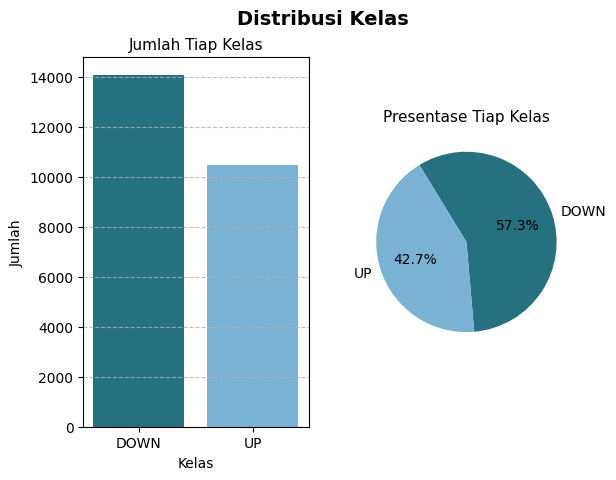

In [ ]:
class_count = df['class'].value_counts()
print('Jumlah kelas (UP): ', class_count['UP'],
      "dan (DOWN): ", class_count['DOWN'], '\n')

# plot bar chart
plt.subplot(1, 2, 1)
plt.bar(class_count.index, class_count.values,
        color = ['#257180', '#7AB2D3'])
plt.title('Jumlah Tiap Kelas', fontsize = 11)
plt.xlabel('Kelas')
plt.ylabel('Jumlah')
plt.grid(axis='y', linestyle = '--', alpha = 0.8)

# plot pie chart
plt.subplot(1, 2, 2)
plt.pie(class_count.values, labels = class_count.index,
        autopct = '%1.1f%%', colors = ['#257180', '#7AB2D3'], startangle = 275)
plt.title('Presentase Tiap Kelas', fontsize = 11)


plt.suptitle("Distribusi Kelas", fontsize = 14, fontweight = 'bold')
plt.show()


### **PEMFORMATAN DATA**

**Encode Target (Class)**

Mengubah tipe kolom 'class' menjadi 1 atau 0

In [ ]:
df['class']=(df['class'] == 'UP').astype(int)
df.head()


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class
0,0.0,2,0.000000,0.056443,0.439155,0.003467,0.422915,0.414912,1
1,0.0,2,0.021277,0.051699,0.415055,0.003467,0.422915,0.414912,1
2,0.0,2,0.042553,0.051489,0.385004,0.003467,0.422915,0.414912,1
3,0.0,2,0.063830,0.045485,0.314639,0.003467,0.422915,0.414912,1
4,0.0,2,0.085106,0.042482,0.251116,0.003467,0.422915,0.414912,0


**Pengujian Korelasi Fitur dengan Target**

In [ ]:
corr = df.corr()


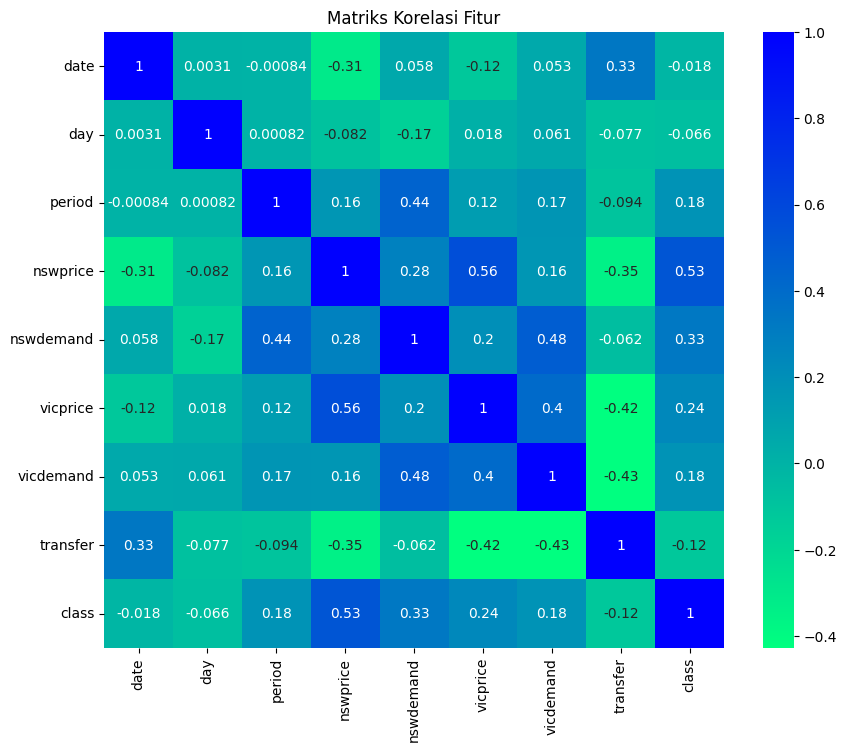

In [ ]:
# Plot matriks korelasi
plt.figure(figsize = (10, 8))
sns.heatmap(corr, annot = True, cmap = 'winter_r', cbar = True)
plt.title('Matriks Korelasi Fitur')
plt.show()


In [ ]:
# Pengambilan fitur dengan kolerasi tinggi terhadap kelas
cor_target = abs(corr['class'])
cor_features = cor_target[cor_target > 0.3]

# set fitur dengan korelasi yang tinggi
data_features = [index for index, value in cor_features.items()]
data_features.remove('class')

# Menampilkan fitur-fitur yang berkolerasi dengan target
print(data_features)


['nswprice', 'nswdemand']


# **KLASIFIKASI BINER DENGAN LOGISTIC REGRESSION**


### **PENJELASAN UMUM**

*Logistic Regression* adalah algoritma dalam *Machine Learning* yang umum digunakan untuk permasalahan klasifikasi. Dapat digunakan untuk memprediksi kategori data **UP** atau **DOWN** berdasarkan harga dan permintaan listrik di wilayah *New South Wales* (NSW) dan *Victoria* (VIC), serta transfer energi antar wilayah. Untuk mencapai tujuan ini, *Logistic Regression* memanfaatkan *Sigmoid Function* atau *Logistic Function* sebagai *cost function*, yang mengonversi output menjadi probabilitas kelas, sehingga model dapat menentukan apakah kondisi pada waktu tertentu berada di kategori **UP** atau **DOWN**.

</br>


### **MODEL MATEMATIS LOGISTIC REGRESSION DENGAN GRADIENT DESCENT**

**Model linear**</br>
Gunakan model linear
\begin{aligned}
z=\mathbf{w}⋅\mathbf{x}+b
\end{aligned}
**(1) Fungsi Sigmoid**</br>
Dalam *Logistic Regression* untuk klasifikasi biner, fungsi sigmoid digunakan untuk memprediksi kelas dari setiap data, di mana fungsi sigmoid dinyatakan sebagai:

\begin{aligned}
\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}} = \frac{1}{1 + e^{-(w_1 \cdot \text{nswprice} + w_2 \cdot \text{nswdemand} + b)}}
\end{aligned}

Dengan menggunakan aproksimasi fungsi *unit-step*, jika nilai sigmoid berada di rentang $0 < \sigma(z) \leq 0.5$, maka data diklasifikasikan sebagai $0$ $DOWN$. Sebaliknya, jika $0.5 < \sigma(z) < 1$, maka data akan diklasifikasikan sebagai $1$ $UP$.</br>

**(2) Cross Entropy untuk menghitung Error**</br>
Untuk menghitung error dari fungsi *fitting*, digunakan *cross entropy error* yang didefinisikan sebagai:

\begin{aligned}
J(w, b) = -\frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]
\end{aligned}

Di sini, $N$ adalah jumlah sampel, dan $J(w, b)$ adalah nilai error keseluruhan yang ingin diminimalkan.</br>

**(3) Mencari nilai Optimal dengan turunan**</br>
Untuk mencari nilai optimalnya menjadi:
\begin{aligned}
\nabla{J} = \begin{bmatrix}
    \frac{∂J}{∂\mathbf{w}} \\
    \frac{∂J}{∂b}
\end{bmatrix} = \begin{bmatrix}
    \frac{1}{N}\Sigma{x_i(\hat{y}-y_i)} \\
    \frac{1}{N}\Sigma{(\hat{y}-y_i)}
\end{bmatrix}
\end{aligned}</br>

**(4) Update parameter dengan *Gradient Descent***</br>
Kemudian, parameter diperbarui menggunakan algoritma *gradient descent*:

\begin{aligned}
w_j & = w_j - \alpha \frac{\partial J}{\partial w_j} \\
b & = b - \alpha \frac{\partial J}{\partial b}
\end{aligned}

Di mana $\alpha$ adalah *learning rate*.

Setelah model terlatih, kelas dari data dapat diprediksi sebagai berikut:

\begin{aligned}
\text{Kelas} = \begin{cases}
      1 & \text{jika } \hat{y} \geq 0.5 \\
      0 & \text{jika } \hat{y} < 0.5
   \end{cases}
\end{aligned}



##**LOGISTIC REGRESSION DENGAN GRADIENT DESCENT**

###**ALGORITMA LOGISTIC REGRESSION**

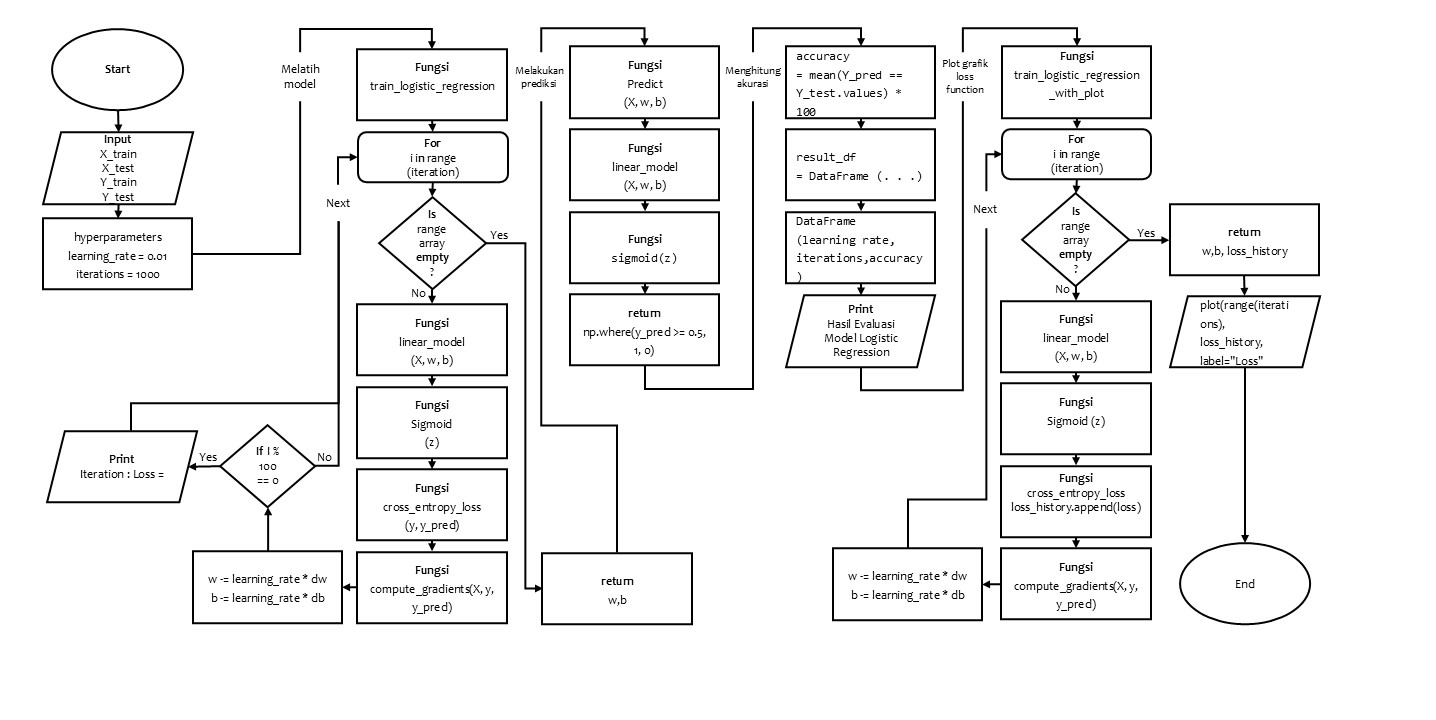

### **IMPLEMENTASI ALGORITMA LOGISTIC REGRESSION**

**Scalling Data**</br>
\begin{aligned}
X_{\text{scaled}} = \frac{X - \text{mean}(X)}{\text{std}(X)}
\end{aligned}</br>
Tahap ini berfungsi menormalkan data sehingga memiliki rata-rata 0 dan standar deviasi 1



In [ ]:
def scale_feature(X):
    mean = np.mean(X, axis = 0)
    std = np.std(X, axis = 0)

    # standardize the data
    X_scaled = (X - mean) / std
    return X_scaled


**Split Data Training dan Testing**

In [ ]:
def train_test_split(X, Y, random_state = 42, test_size = 0.2):
    #Ambil jummlah sample
    n_samples = X.shape[0]

    #Ambil seed untuk geneator angka random
    np.random.seed(random_state)

    #Shuffle indices
    shuffled_indices = np.random.permutation(np.arange(n_samples))

    #Menentukan ukuran test set
    test_size = int(test_size * n_samples)

    #Split data training dan testing
    test_indices = shuffled_indices[:test_size]
    train_indices = shuffled_indices[test_size:]

    #Split fitur dan target array menjadi testing dan tranining set
    X_train, X_test = X[train_indices], X[test_indices]
    Y_train, Y_test = Y.iloc[train_indices], Y.iloc[test_indices]

    return X_train, X_test, Y_train, Y_test


**Implementasi Logistic Regression**

In [ ]:
X = df[data_features].values
y = df['class']

X_scaled = scale_feature(X)

X_train, X_test, Y_train, Y_test = train_test_split(X_scaled, y, random_state=42, test_size=0.2)

# Mendefinisikan fungsi model Logistic Regression
def linear_model(X, w, b):
    return np.dot(X, w) + b

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def cross_entropy_loss(y, y_pred):
    N = y.shape[0]
    loss = -np.mean(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
    return loss

def compute_gradients(X, y, y_pred):
    N = y.shape[0]
    dw = np.dot(X.T, (y_pred - y)) / N
    db = np.sum(y_pred - y) / N
    return dw, db

def train_logistic_regression(X, y, learning_rate, iterations):
    w = np.zeros(X.shape[1])
    b = 0
    for i in range(iterations):
        z = linear_model(X, w, b)
        y_pred = sigmoid(z)
        loss = cross_entropy_loss(y, y_pred)
        dw, db = compute_gradients(X, y, y_pred)
        w -= learning_rate * dw
        b -= learning_rate * db
        if i % 100 == 0:
            print(f"Iteration {i}: Loss = {loss}")
    return w, b

def predict(X, w, b):
    z = linear_model(X, w, b)
    y_pred = sigmoid(z)
    return np.where(y_pred >= 0.5, 1, 0)

# Menetapkan hyperparameters
learning_rate = 0.01
iterations = 1000

# Melatih Model
w, b = train_logistic_regression(X_train, Y_train.values, learning_rate, iterations)

# Melakukan prediksi pada data pengujian
Y_pred = predict(X_test, w, b)

# Menghitung akurasi
accuracy = np.mean(Y_pred == Y_test.values) * 100
result_df = pd.DataFrame({
    "Hyperparameter": ["Learning Rate", "Iterations", "Accuracy"],
    "Value": [learning_rate, iterations, f"{accuracy:.2f}%"]
})

# Menampilkan hasil
print("\nHasil Evaluasi Model Logistic Regression")
print(result_df.to_string(index=False))


Iteration 0: Loss = 0.6931471805599453
Iteration 100: Loss = 0.6193382142507285
Iteration 200: Loss = 0.5769022281195701
Iteration 300: Loss = 0.5504228607608672
Iteration 400: Loss = 0.5327953845703104
Iteration 500: Loss = 0.5204706221761892
Iteration 600: Loss = 0.511521649244348
Iteration 700: Loss = 0.5048281608944388
Iteration 800: Loss = 0.49970148790129404
Iteration 900: Loss = 0.49569845712224725

Hasil Evaluasi Model Logistic Regression
Hyperparameter  Value
 Learning Rate   0.01
    Iterations   1000
      Accuracy 78.37%


**Plot Grafik Loss function**

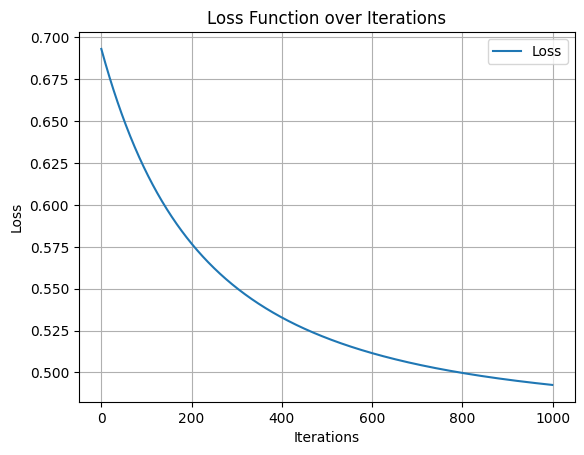

In [ ]:
# Melatih model dengan tracking loss
def train_logistic_regression_with_plot(X, y, learning_rate, iterations):
    w = np.zeros(X.shape[1])
    b = 0
    loss_history = []
    for i in range(iterations):
        z = linear_model(X, w, b)
        y_pred = sigmoid(z)
        loss = cross_entropy_loss(y, y_pred)
        loss_history.append(loss)
        dw, db = compute_gradients(X, y, y_pred)
        w -= learning_rate * dw
        b -= learning_rate * db
    return w, b, loss_history

w, b, loss_history = train_logistic_regression_with_plot(X_train, Y_train.values, learning_rate, iterations)

# Plot grafik loss function
import matplotlib.pyplot as plt

plt.plot(range(iterations), loss_hist ory, label="Loss")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Loss Function over Iterations")
plt.legend()
plt.grid(True)
plt.show()


**Evaluasi Model**

**(1) Evaluasi dengan *Confusion Matriks***

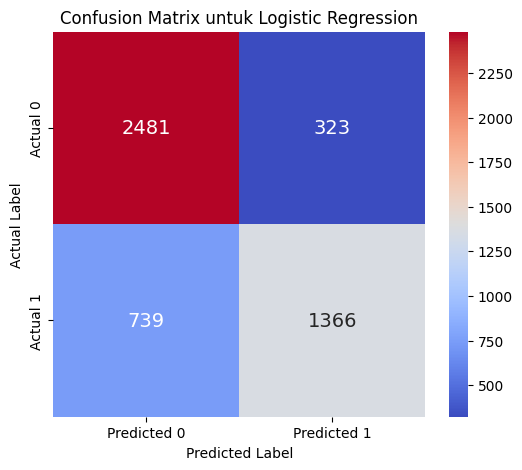

In [ ]:
# Fungsi untuk menghitung confusion matrix
def confusion_matrix(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))  # True Positives
    TN = np.sum((y_true == 0) & (y_pred == 0))  # True Negatives
    FP = np.sum((y_true == 0) & (y_pred == 1))  # False Positives
    FN = np.sum((y_true == 1) & (y_pred == 0))  # False Negatives

    # Menyusun confusion matriks
    confusion_mat = np.array([[TN, FP], [FN, TP]])
    return confusion_mat

# Menghitung confusion matriks
conf_matrix = confusion_matrix(Y_test.values, Y_pred)

# Menyusun DataFrame
confusion_df = pd.DataFrame(conf_matrix, index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"])

# Visualisasi Confusion Matrix dengan Seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_df, annot=True, fmt="d", cmap="coolwarm", cbar=True, annot_kws={"size": 14})
plt.title("Confusion Matrix untuk Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


**(2) Evaluasi dengan metrik presisi, recall, F1-score, dan *support***

In [ ]:
from tabulate import tabulate

# Fungsi untuk menghitung metrik evaluasi dari hasil confusion matrix
def calculate_metrics_from_confusion_matrix(conf_matrix):
    TN, FP = conf_matrix[0, 0], conf_matrix[0, 1]
    FN, TP = conf_matrix[1, 0], conf_matrix[1, 1]

    # Menghitung metrik evaluasi
    precision_0 = TN / (TN + FP) if (TN + FP) > 0 else 0
    recall_0 = TN / (TN + FN) if (TN + FN) > 0 else 0
    f1_0 = 2 * precision_0 * recall_0 / (precision_0 + recall_0) if (precision_0 + recall_0) > 0 else 0

    precision_1 = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall_1 = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_1 = 2 * precision_1 * recall_1 / (precision_1 + recall_1) if (precision_1 + recall_1) > 0 else 0

    # Mendapatkan support
    support_0 = TN + FP
    support_1 = FN + TP

    # Rata-rata presisi, recall, dan F1-score
    macro_precision = (precision_0 + precision_1) / 2
    macro_recall = (recall_0 + recall_1) / 2
    macro_f1 = (f1_0 + f1_1) / 2

    weighted_precision = (precision_0 * support_0 + precision_1 * support_1) / (support_0 + support_1)
    weighted_recall = (recall_0 * support_0 + recall_1 * support_1) / (support_0 + support_1)
    weighted_f1 = (f1_0 * support_0 + f1_1 * support_1) / (support_0 + support_1)

    # Akurasi
    accuracy = (TP + TN) / (TP + TN + FP + FN)

    # Menyusun hasil
    results = [
        ["0", precision_0, recall_0, f1_0, support_0],
        ["1", precision_1, recall_1, f1_1, support_1],
        ["accuracy", "-", accuracy, "-", support_0 + support_1],
        ["macro avg", macro_precision, macro_recall, macro_f1, support_0 + support_1],
        ["weighted avg", weighted_precision, weighted_recall, weighted_f1, support_0 + support_1]
    ]

    headers = ["Class", "Precision", "Recall", "F1-Score", "Support"]
    print("\nConfusion Matrix Report:")
    print(tabulate(results, headers=headers, tablefmt="pretty"))

conf_matrix = confusion_matrix(Y_test.values, Y_pred)

calculate_metrics_from_confusion_matrix(conf_matrix)



Confusion Matrix Report:
+--------------+--------------------+--------------------+--------------------+---------+
|    Class     |     Precision      |       Recall       |      F1-Score      | Support |
+--------------+--------------------+--------------------+--------------------+---------+
|      0       | 0.8848074179743224 | 0.7704968944099378 | 0.8237051792828685 |  2804   |
|      1       | 0.8087625814091178 | 0.6489311163895487 | 0.7200843437005799 |  2105   |
|   accuracy   |         -          | 0.7836626604196374 |         -          |  4909   |
|  macro avg   |  0.84678499969172  | 0.7097140053997433 | 0.7718947614917242 |  4909   |
| weighted avg | 0.8521990698444069 | 0.7183689737065524 | 0.7792721259317343 |  4909   |
+--------------+--------------------+--------------------+--------------------+---------+
